# 02. Exploratory analysis

**Question: What patterns in emergency department visits should we consider when building a forecasting model?**

In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd().parent
path = project_dir / "data" / "processed" / "df_cleaned.parquet"

try:
    df = pd.read_parquet(path)
    # If you've run Notebook 1 all the way through, you shouldn't have any problems with this try
except (FileNotFoundError, ImportError):  # Otherwise, we can reapply the transformations here
    file = project_dir / "data" / "raw" / "emergency-visits-2017-2023.csv"
    df_raw = pd.read_csv(file, sep=";")
    df_fr = df_raw[df_raw["dep"] == "69"].copy()
    df_fr["date"] = pd.to_datetime(df_fr["date"])
    df_fr = df_fr.sort_values("date")
    df_fr = df_fr.set_index("date")
    df = df_fr.rename(columns={"nb_passages": "visits"})
    df = df[["visits"]]

### 1. How has the number of visits changed over time?

#### Daily visits and moving averages

The raw daily series is noisy, so we add 7-day and 30-day moving averages. The 7-day average smooths the weekly pattern, while the 30-day average highlights longer-term trends and seasonality. The shaded area marks the first COVID-19 lockdown in 2020.

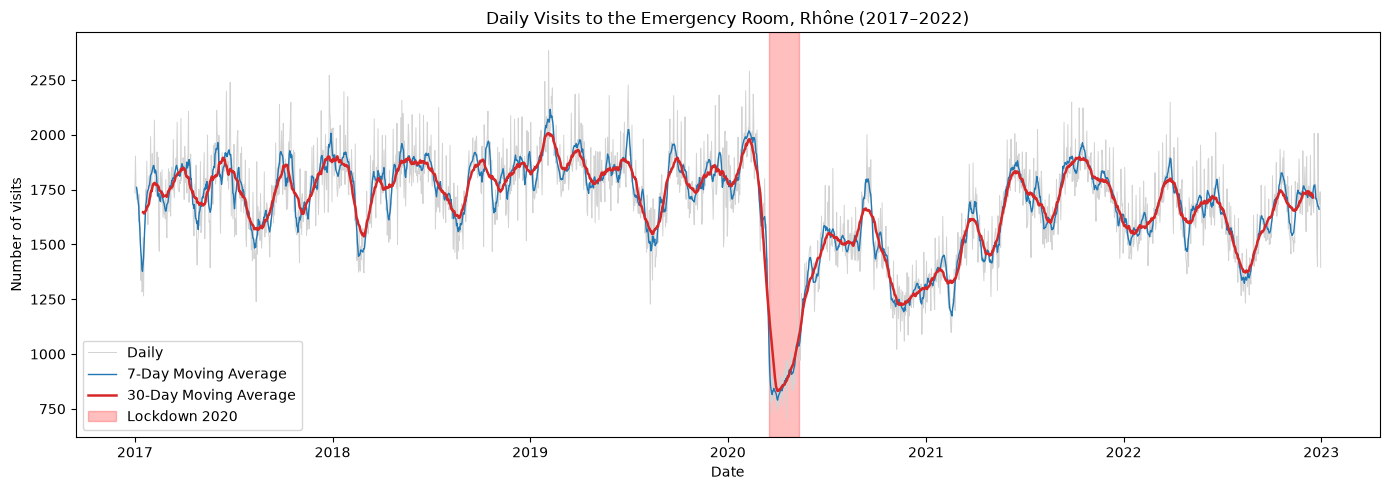

In [12]:
visits = df.loc["2017-01-01":"2022-12-31", "visits"]
roll_7 = visits.rolling(window=7, center=True).mean()
roll_30 = visits.rolling(window=30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(visits.index, visits, color="lightgrey", linewidth=0.7, label="Daily")
ax.plot(roll_7.index, roll_7, color="tab:blue", linewidth=1, label="7-Day Moving Average")
ax.plot(roll_30.index, roll_30, color="tab:red", linewidth=1.8, label="30-Day Moving Average")


ax.axvspan("2020-03-17", "2020-05-11", color="red", alpha=0.25, label="Lockdown 2020")
ax.set_title("Daily Visits to the Emergency Room, Rhône (2017–2022)")
ax.set_xlabel("Date")
ax.set_ylabel("Number of visits")
ax.legend()
plt.tight_layout()
plt.show()


The raw data reveal significant daily volatility, while the 7- and 30-day moving averages help identify the underlying trend.

Activity remained relatively stable and seasonal until early 2020, with average volumes ranging from 1,700 to 1,800 visits per day. The lockdown period marked a major turning point: there was a sharp collapse in visitor numbers, which fell below 800 visits per day. After this drop, visitor numbers gradually rebounded but remained, over the 2021–2022 period, generally below the levels observed before the health crisis.

### Year-by-year comparison and seasonal patterns

To understand trends within a single year and perhaps identify seasonal patterns, we plot the 30-day moving average of the number of visits for each year, and we aggregate all the data on the same day-of-year axis.

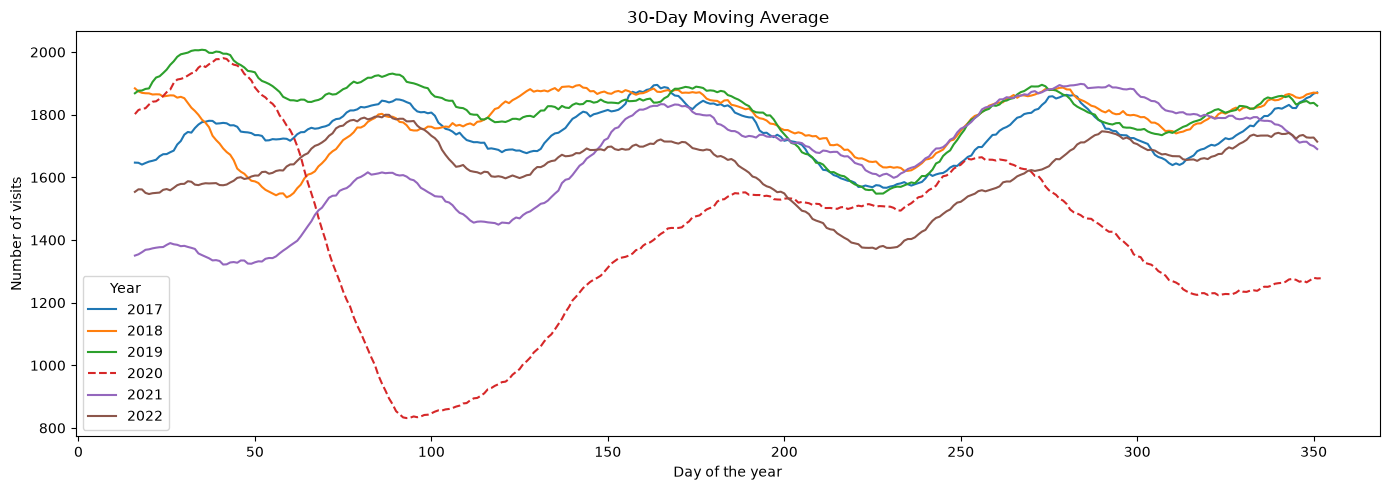

In [20]:
fig, ax = plt.subplots(figsize=(14, 5))

for year, group in visits.groupby(visits.index.year):
    smooth = group.rolling(window=30, center=True).mean()
    ax.plot(smooth.index.day_of_year, smooth.values, label=str(year),
            linestyle="--" if year == 2020 else "-")

ax.set_title("30-Day Moving Average")
ax.set_xlabel("Day of the year")
ax.set_ylabel("Number of visits")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

This graph highlights three key findings:

1. A recurring seasonal pattern (excluding 2020): The years 2017, 2018, 2019, 2021, and 2022 show broadly similar trends. Typically, there is a winter trough (between days 50 and 100), followed by a spring uptick and a summer plateau, before another peak in the fall. Visitor numbers generally remain between 1,500 and 1,900 visits per day.

2. The anomaly of 2020 (dotted line): The year 2020 stands out dramatically. While it began in line with previous years, the curve plummeted sharply around day 70 (mid-March), reaching a historic low of approximately 850 visits. The recovery was then slow and gradual, never regaining the levels seen in other years for the remainder of the year.

3. An atypical 2021: The 2021 curve reveals an interesting temporal shift. The usual seasonal trough appears to have shifted and intensified toward the end of the year (between days 200 and 250), reaching levels close to 1,600 visits, which suggests a persistent effect or different dynamics following the health crisis.